In [1]:
import os, zipfile

from google.colab import drive
if not os.path.isdir("/content/drive/MyDrive"):
    drive.mount("/content/drive")

ZIP = "/content/drive/MyDrive/lifeguard_datasets/MOBDrone/MOBDrone_videos.zip"
EXPECTED_SIZE = 5455391169

if not os.path.exists(ZIP):
    raise SystemExit(f"STOP: archive not found: {ZIP}")
if os.path.getsize(ZIP) != EXPECTED_SIZE:
    raise SystemExit(f"STOP: size {os.path.getsize(ZIP)} != expected {EXPECTED_SIZE}")

z = zipfile.ZipFile(ZIP)
names = z.namelist()
exts = {}
for n in names:
    e = os.path.splitext(n)[1].lower() or "(none)"
    exts[e] = exts.get(e, 0) + 1
total_uncompressed = sum(i.file_size for i in z.infolist())

print("files in archive:", len(names))
print("extensions:", exts)
print("total uncompressed size: %.2f GB" % (total_uncompressed / 1e9))
print("first 5 entries:", names[:5])

bad = [n for n in names if ".." in n or n.startswith(("/", "\\"))]
print("path-traversal / suspicious entries:", bad or "none")

files in archive: 66
extensions: {'.mp4': 66}
total uncompressed size: 5.46 GB
first 5 entries: ['video_split_fullhd/DJI_0804_0001_30m_1.mp4', 'video_split_fullhd/DJI_0804_0001_30m_2.mp4', 'video_split_fullhd/DJI_0804_0001_30m_3.mp4', 'video_split_fullhd/DJI_0804_0002_30m_1.mp4', 'video_split_fullhd/DJI_0804_0002_30m_2.mp4']
path-traversal / suspicious entries: none


In [2]:
import os, zipfile, shutil

ZIP = "/content/drive/MyDrive/lifeguard_datasets/MOBDrone/MOBDrone_videos.zip"
VDIR = "/content/drive/MyDrive/lifeguard_datasets/MOBDrone/videos"

z = zipfile.ZipFile(ZIP)
video_names = [n for n in z.namelist() if n.lower().endswith((".mp4", ".mov", ".avi", ".mkv"))]
print("video entries in archive:", len(video_names))

if os.path.isdir(VDIR) and os.listdir(VDIR):
    have = set(os.listdir(VDIR))
    want = {os.path.basename(n) for n in video_names}
    if have == want:
        print(f"SKIP: videos/ already has all {len(want)} videos.")
        raise SystemExit(0)
    raise SystemExit(f"STOP: videos/ is partial/conflicting ({len(have)} vs {len(want)}). Inspect before extracting.")

os.makedirs(VDIR, exist_ok=True)
for n in video_names:
    out = os.path.join(VDIR, os.path.basename(n))
    with z.open(n) as src, open(out, "wb") as dst:
        shutil.copyfileobj(src, dst)
    print("extracted:", os.path.basename(n), os.path.getsize(out), "bytes")

on_disk = set(os.listdir(VDIR))
want = {os.path.basename(n) for n in video_names}
print("extracted:", len(on_disk), "| expected:", len(want), "| match:", on_disk == want)

video entries in archive: 66
extracted: DJI_0804_0001_30m_1.mp4 54684439 bytes
extracted: DJI_0804_0001_30m_2.mp4 33850490 bytes
extracted: DJI_0804_0001_30m_3.mp4 12392566 bytes
extracted: DJI_0804_0002_30m_1.mp4 69868663 bytes
extracted: DJI_0804_0002_30m_2.mp4 67838190 bytes
extracted: DJI_0804_0003_10m.mp4 41295137 bytes
extracted: DJI_0804_0004_20m.mp4 62917818 bytes
extracted: DJI_0804_0005_30m.mp4 60772428 bytes
extracted: DJI_0804_0006_40m.mp4 63507857 bytes
extracted: DJI_0804_0007_50m.mp4 62529444 bytes
extracted: DJI_0804_0008_20m.mp4 64134892 bytes
extracted: DJI_0804_0009_40m.mp4 81217627 bytes
extracted: DJI_0804_0010_60m.mp4 71730345 bytes
extracted: DJI_0804_0011_30m_1.mp4 78634413 bytes
extracted: DJI_0804_0011_30m_2.mp4 45922474 bytes
extracted: DJI_0804_0012_50m_1.mp4 90703472 bytes
extracted: DJI_0804_0012_50m_2.mp4 2814641 bytes
extracted: DJI_0804_0012_50m_3.mp4 78548882 bytes
extracted: DJI_0804_0013_40m.mp4 39188939 bytes
extracted: DJI_0804_0014_50m_1.mp4 67479

In [3]:
import os, glob, csv, subprocess

VDIR = "/content/drive/MyDrive/lifeguard_datasets/MOBDrone/videos"
REP = "/content/drive/MyDrive/lifeguard_datasets/MOBDrone/reports"
os.makedirs(REP, exist_ok=True)

videos = sorted(glob.glob(f"{VDIR}/*"))
rows = []
for v in videos:
    stem = os.path.splitext(os.path.basename(v))[0]
    p = subprocess.run(["ffprobe","-v","error","-select_streams","v:0",
        "-show_entries","stream=width,height,r_frame_rate,nb_frames,duration",
        "-of","csv=p=0", v], capture_output=True, text=True)
    out = p.stdout.strip()
    if p.returncode != 0 or not out:
        rows.append([stem, os.path.getsize(v), "UNREADABLE", "", "", "", "", ""])
    else:
        parts = out.split(",")
        rows.append([stem, os.path.getsize(v), "readable", *parts[:5]])

with open(f"{REP}/video_inventory.csv", "w", newline="") as f:
    w = csv.writer(f); w.writerow(["video","size_bytes","status","width","height","fps","nb_frames","duration_s"])
    w.writerows(rows)

unreadable = [r for r in rows if r[2] != "readable"]
print("videos:", len(rows), "| readable:", len(rows)-len(unreadable), "| unreadable:", len(unreadable))
for r in unreadable: print("  UNREADABLE:", r[0])

with open(f"{REP}/video_inventory.md", "w") as f:
    f.write("# MOBDrone video inventory\n\n| video | size(MB) | status | width | height | fps | frames | duration(s) |\n|---|---|---|---|---|---|---|---|\n")
    for r in rows:
        f.write(f"| {r[0]} | {r[1]/1e6:.1f} | {r[2]} | {r[3]} | {r[4]} | {r[5]} | {r[6]} | {r[7]} |\n")
print("reports ->", REP)

videos: 66 | readable: 66 | unreadable: 0
reports -> /content/drive/MyDrive/lifeguard_datasets/MOBDrone/reports


In [4]:
import os, glob

candidates = ["/content/drive/MyDrive/lifeguard_datasets/MOBDrone/annotations_5_custom_classes.json"]
found = [c for c in candidates if os.path.exists(c)]
for p in glob.glob("/content/drive/MyDrive/lifeguard_datasets/MOBDrone/**/annotations_5_custom_classes.json", recursive=True):
    if p not in found: found.append(p)

if found:
    for f in found:
        print("FOUND:", f, os.path.getsize(f), "bytes")
else:
    print("NOT FOUND. Download URL (official Zenodo record 5996890):")
    print("  https://zenodo.org/records/5996890/files/annotations_5_custom_classes.json?download=1")
    print("  expected size: 60485062 bytes")

NOT FOUND. Download URL (official Zenodo record 5996890):
  https://zenodo.org/records/5996890/files/annotations_5_custom_classes.json?download=1
  expected size: 60485062 bytes


In [5]:
import os, subprocess

DEST = "/content/drive/MyDrive/lifeguard_datasets/MOBDrone/annotations_5_custom_classes.json"
URL  = "https://zenodo.org/records/5996890/files/annotations_5_custom_classes.json?download=1"
EXPECTED = 60485062

if os.path.exists(DEST) and os.path.getsize(DEST) == EXPECTED:
    print("SKIP: already present and complete.")
elif os.path.exists(DEST):
    raise SystemExit(f"STOP: existing file size {os.path.getsize(DEST)} != expected {EXPECTED}. Inspect before overwriting.")
else:
    subprocess.run(["wget", "-c", "-O", DEST, URL], check=True)
    print("downloaded:", DEST, os.path.getsize(DEST), "bytes")

downloaded: /content/drive/MyDrive/lifeguard_datasets/MOBDrone/annotations_5_custom_classes.json 60485062 bytes


In [6]:
import json, collections

DEST = "/content/drive/MyDrive/lifeguard_datasets/MOBDrone/annotations_5_custom_classes.json"
d = json.load(open(DEST))

print("top-level keys:", list(d.keys()))
print("images:", len(d.get("images", [])))
print("annotations:", len(d.get("annotations", [])))
print("categories:", [(c["id"], c["name"]) for c in d.get("categories", [])])

imgs = d.get("images", [])
print("\nfirst image record (all fields):", imgs[0] if imgs else "none")
print("\nfirst 10 file_name values:")
for im in imgs[:10]:
    print("  ", im.get("file_name"))

print("\nimage keys:", list(imgs[0].keys()) if imgs else "none")

# distinct video prefixes (from file_name path)
prefixes = collections.Counter()
for im in imgs:
    fn = im.get("file_name") or ""
    prefixes[fn.split("/")[0]] += 1
print("\ndistinct video prefixes:", len(prefixes))
print("sample prefixes:", prefixes.most_common(5))

ann_cls = collections.Counter(a.get("category_id") for a in d.get("annotations", []))
print("\nboxes per category_id:", dict(ann_cls))

top-level keys: ['categories', 'images', 'annotations']
images: 126170
annotations: 181689
categories: [(1, 'person'), (2, 'boat'), (3, 'surfboard'), (4, 'wood'), (5, 'life_buoy')]

first image record (all fields): {'id': 1, 'width': 1920, 'height': 1012, 'file_name': 'DJI_0804_0001_30m_1_000000.PNG', 'license': 0, 'flickr_url': '', 'coco_url': '', 'date_captured': 0}

first 10 file_name values:
   DJI_0804_0001_30m_1_000000.PNG
   DJI_0804_0001_30m_1_000001.PNG
   DJI_0804_0001_30m_1_000002.PNG
   DJI_0804_0001_30m_1_000003.PNG
   DJI_0804_0001_30m_1_000004.PNG
   DJI_0804_0001_30m_1_000005.PNG
   DJI_0804_0001_30m_1_000006.PNG
   DJI_0804_0001_30m_1_000007.PNG
   DJI_0804_0001_30m_1_000008.PNG
   DJI_0804_0001_30m_1_000009.PNG

image keys: ['id', 'width', 'height', 'file_name', 'license', 'flickr_url', 'coco_url', 'date_captured']

distinct video prefixes: 126170
sample prefixes: [('DJI_0804_0001_30m_1_000000.PNG', 1), ('DJI_0804_0001_30m_1_000001.PNG', 1), ('DJI_0804_0001_30m_1_0000

In [7]:
import json, re, collections, os, glob

DEST = "/content/drive/MyDrive/lifeguard_datasets/MOBDrone/annotations_5_custom_classes.json"
d = json.load(open(DEST))

id_to_file = {im["id"]: im["file_name"] for im in d["images"]}
stem = lambda fn: re.sub(r'_\d{6}\.PNG$', '', fn)

pos = collections.Counter()          # image_id -> box count
for a in d["annotations"]:
    pos[a["image_id"]] += 1

pos_per_video = collections.Counter()
for iid in pos:
    pos_per_video[stem(id_to_file[iid])] += 1

print("images total:", len(d["images"]))
print("images with >=1 box (positive):", len(pos))
print("images with 0 boxes (background):", len(d["images"]) - len(pos))
print("boxes:", len(d["annotations"]))
print("avg boxes per positive frame: %.2f" % (len(d["annotations"]) / max(1, len(pos))))

vals = sorted(pos_per_video.values())
print("positive frames per video: min %d / median %d / max %d" % (vals[0], vals[len(vals)//2], vals[-1]))

vids = {os.path.splitext(os.path.basename(p))[0]
        for p in glob.glob("/content/drive/MyDrive/lifeguard_datasets/MOBDrone/videos/*")}
stems = {stem(im["file_name"]) for im in d["images"]}
print("\nstems:", len(stems), "| videos:", len(vids))
print("stems WITHOUT a video file:", sorted(stems - vids))
print("videos WITHOUT an annotation stem:", sorted(vids - stems))

images total: 126170
images with >=1 box (positive): 91194
images with 0 boxes (background): 34976
boxes: 181689
avg boxes per positive frame: 1.99
positive frames per video: min 57 / median 1235 / max 4384

stems: 66 | videos: 66
stems WITHOUT a video file: ['DJI_0915_0007_40m']
videos WITHOUT an annotation stem: ['DJI_0915_0007_40']


In [8]:
import json, re, subprocess, os

DEST = "/content/drive/MyDrive/lifeguard_datasets/MOBDrone/annotations_5_custom_classes.json"
d = json.load(open(DEST))
stem = lambda fn: re.sub(r'_\d{6}\.PNG$', '', fn)

def count_images(target):
    imgs = [im for im in d["images"] if stem(im["file_name"]) == target]
    if imgs:
        idxs = [int(re.search(r'_(\d{6})\.PNG$', im["file_name"]).group(1)) for im in imgs]
        return len(imgs), min(idxs), max(idxs)
    return 0, None, None

def ffprobe(path):
    p = subprocess.run(["ffprobe","-v","error","-select_streams","v:0",
        "-show_entries","stream=r_frame_rate,nb_frames,duration","-of","csv=p=0", path],
        capture_output=True, text=True)
    return p.stdout.strip()

VDIR = "/content/drive/MyDrive/lifeguard_datasets/MOBDrone/videos"

n, lo, hi = count_images("DJI_0915_0007_40m")
print(f"annotation 'DJI_0915_0007_40m': {n} images, index {lo}..{hi}")
print(f"video    'DJI_0915_0007_40.mp4':", ffprobe(f"{VDIR}/DJI_0915_0007_40.mp4"))

# also re-check the known frame-count-mismatch clip
n2, lo2, hi2 = count_images("DJI_0804_0017_40m")
print(f"\nannotation 'DJI_0804_0017_40m': {n2} images, index {lo2}..{hi2}")
print(f"video    'DJI_0804_0017_40m.mp4':", ffprobe(f"{VDIR}/DJI_0804_0017_40m.mp4"))

annotation 'DJI_0915_0007_40m': 5406 images, index 0..5405
video    'DJI_0915_0007_40.mp4': 30000/1001,180.354633,5406

annotation 'DJI_0804_0017_40m': 1589 images, index 0..1588
video    'DJI_0804_0017_40m.mp4': 2997/100,53.040874,1593


In [9]:
import os, json, re, subprocess, shutil

# 1) confirm the tools exist (do not assume they are installed)
for tool in ("ffmpeg", "ffprobe"):
    print(f"{tool}:", shutil.which(tool) or "NOT FOUND")

DEST = "/content/drive/MyDrive/lifeguard_datasets/MOBDrone/annotations_5_custom_classes.json"
VDIR = "/content/drive/MyDrive/lifeguard_datasets/MOBDrone/videos"
d = json.load(open(DEST))
stem = lambda fn: re.sub(r'_\d{6}\.PNG$', '', fn)

def annotation_info(target):
    imgs = [im for im in d["images"] if stem(im["file_name"]) == target]
    if not imgs:
        return 0, None, None
    idxs = [int(re.search(r'_(\d{6})\.PNG$', im["file_name"]).group(1)) for im in imgs]
    return len(imgs), min(idxs), max(idxs)

def decoded_frame_count(path):
    # decode every frame and count them (reliable; ignores container metadata)
    p = subprocess.run(["ffmpeg", "-i", path, "-map", "0:v:0", "-f", "null", "-"],
                       capture_output=True, text=True)
    m = re.search(r"frame=\s*(\d+)", p.stderr)
    return int(m.group(1)) if m else None

cases = [
    ("DJI_0915_0007_40m", "DJI_0915_0007_40.mp4"),
    ("DJI_0804_0017_40m", "DJI_0804_0017_40m.mp4"),
]

for ann_stem, vid_name in cases:
    n, lo, hi = annotation_info(ann_stem)
    dec = decoded_frame_count(f"{VDIR}/{vid_name}")
    print(f"\nannotation '{ann_stem}': {n} images, index {lo}..{hi}")
    print(f"video '{vid_name}': decoded frame count = {dec}")
    if n and dec:
        diff = dec - n
        print(f"decoded - annotated = {diff:+d}  -> "
              f"{'counts match (supports same-clip hypothesis)' if diff == 0 else 'counts DIFFER - investigate'}")

ffmpeg: /usr/bin/ffmpeg
ffprobe: /usr/bin/ffprobe

annotation 'DJI_0915_0007_40m': 5406 images, index 0..5405
video 'DJI_0915_0007_40.mp4': decoded frame count = 0

annotation 'DJI_0804_0017_40m': 1589 images, index 0..1588
video 'DJI_0804_0017_40m.mp4': decoded frame count = 0


In [10]:
import subprocess, re

def count(path):
    # decode every frame, discard output, count via the progress line
    p = subprocess.run(
        ["ffmpeg", "-hide_banner", "-i", path, "-map", "0:v:0", "-f", "null", "-"],
        capture_output=True, text=True)
    occ = re.findall(r"frame=\s*(\d+)", p.stderr)   # ALL progress updates
    print("  return code:", p.returncode)
    tail = [l.strip() for l in p.stderr.splitlines() if l.strip()][-2:]
    for l in tail: print("    ", l)
    return int(occ[-1]) if occ else None            # LAST one = final total

for vid in ["DJI_0915_0007_40.mp4", "DJI_0804_0017_40m.mp4"]:
    print(f"\n=== {vid} ===")
    n = count(f"/content/drive/MyDrive/lifeguard_datasets/MOBDrone/videos/{vid}")
    print("  total decoded frames:", n)


=== DJI_0915_0007_40.mp4 ===
  return code: 0
     [out#0/null @ 0x57bfeaaf7b40] video:2534kB audio:0kB subtitle:0kB other streams:0kB global headers:0kB muxing overhead: unknown
     frame= 5406 fps=483 q=-0.0 Lsize=N/A time=00:03:00.31 bitrate=N/A speed=16.1x
  total decoded frames: 5406

=== DJI_0804_0017_40m.mp4 ===
  return code: 0
     [out#0/null @ 0x5c39871209c0] video:745kB audio:0kB subtitle:0kB other streams:0kB global headers:0kB muxing overhead: unknown
     frame= 1589 fps=323 q=-0.0 Lsize=N/A time=00:00:52.98 bitrate=N/A speed=10.8x
  total decoded frames: 1589


first annotation record (to confirm bbox format): {'id': 1, 'image_id': 62, 'category_id': 1, 'segmentation': [], 'area': 829.644000000002, 'bbox': [3.69, 593.06, 28.2, 29.42], 'iscrowd': 0, 'attributes': {'occluded': False, 'track_id': 0, 'keyframe': True}}
frames to check: [0, 688, 689, 690, 1351, 2703, 4054, 5405]


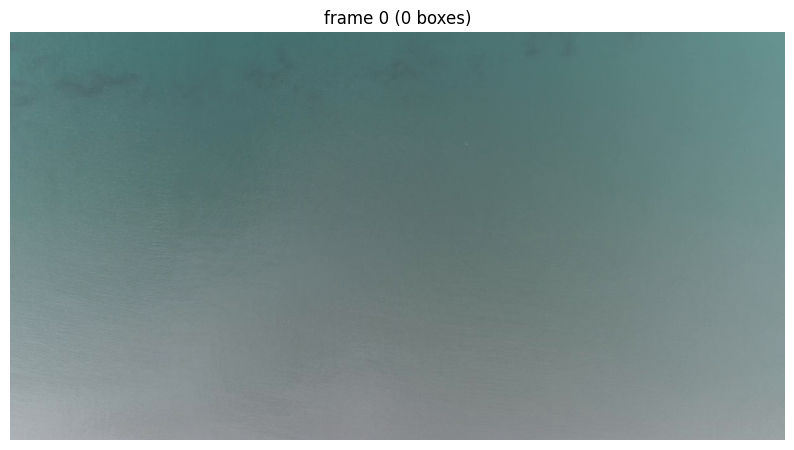

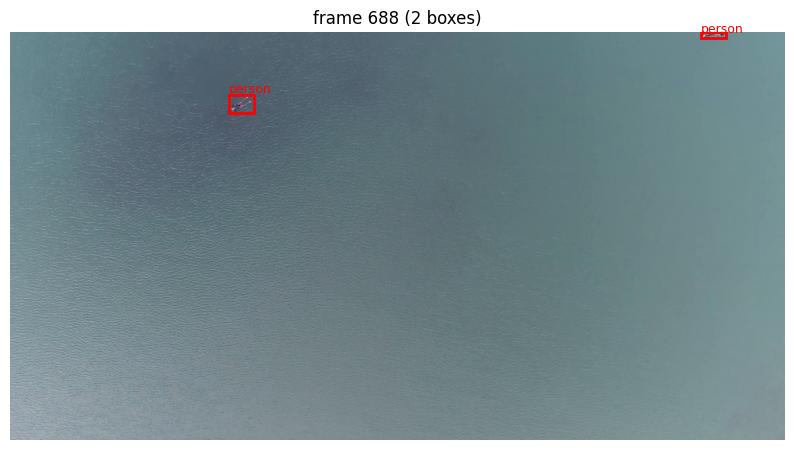

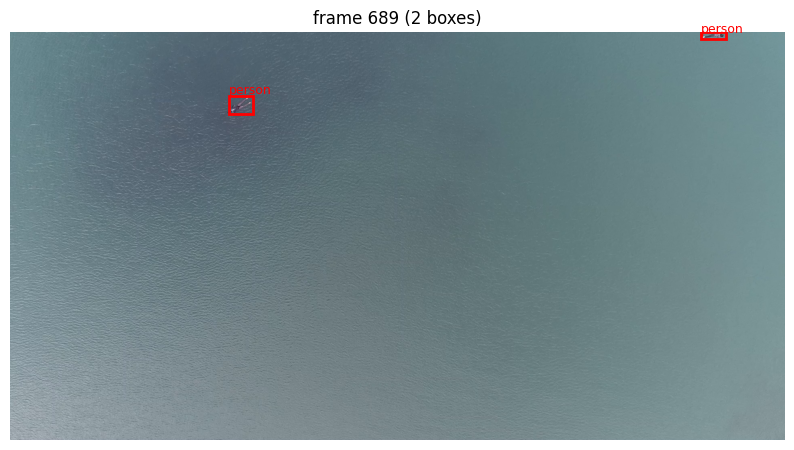

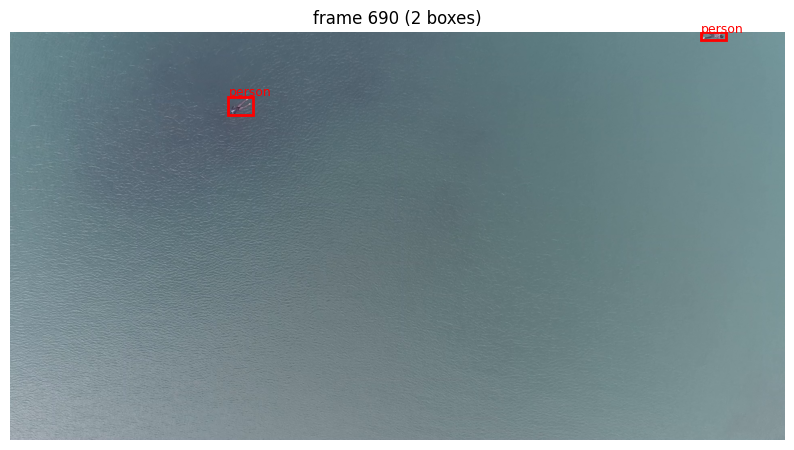

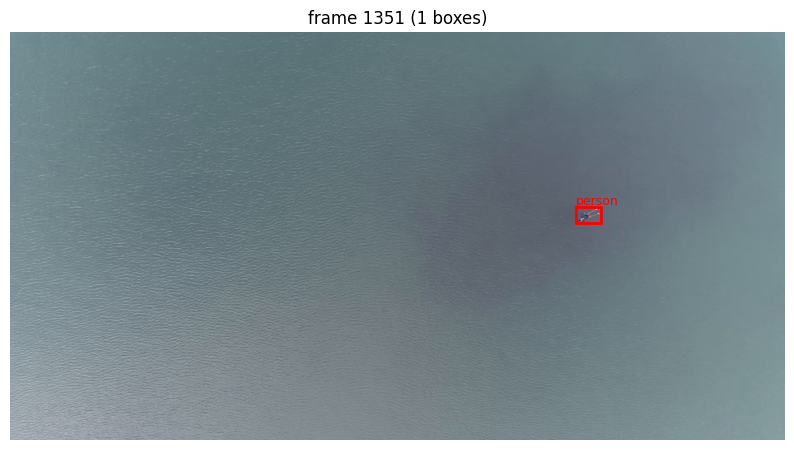

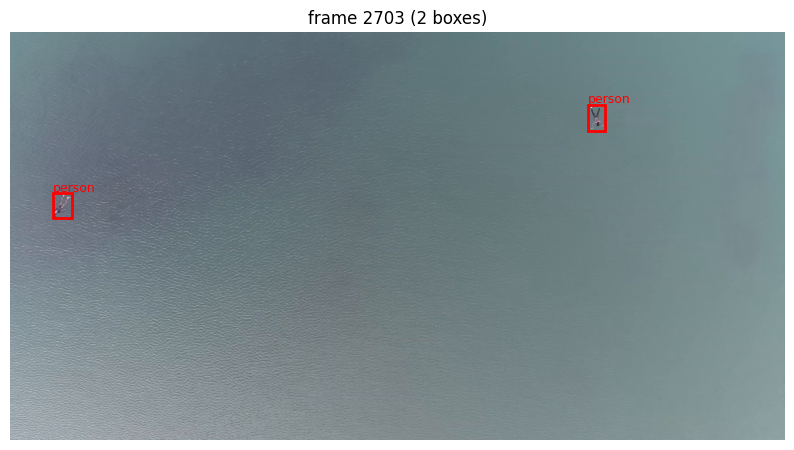

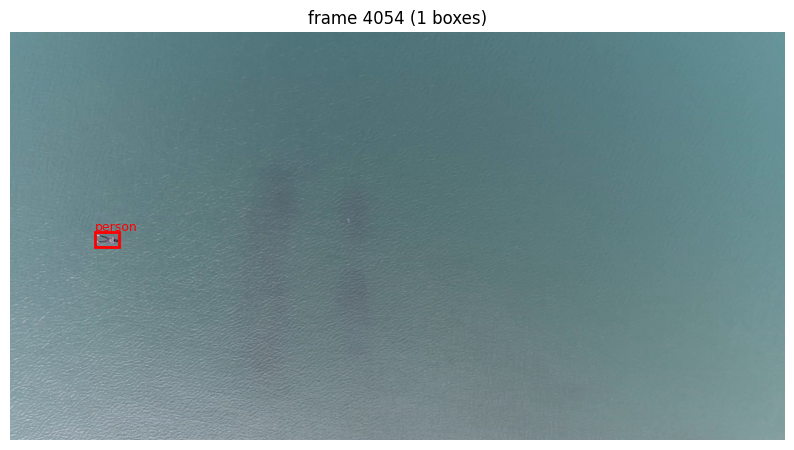

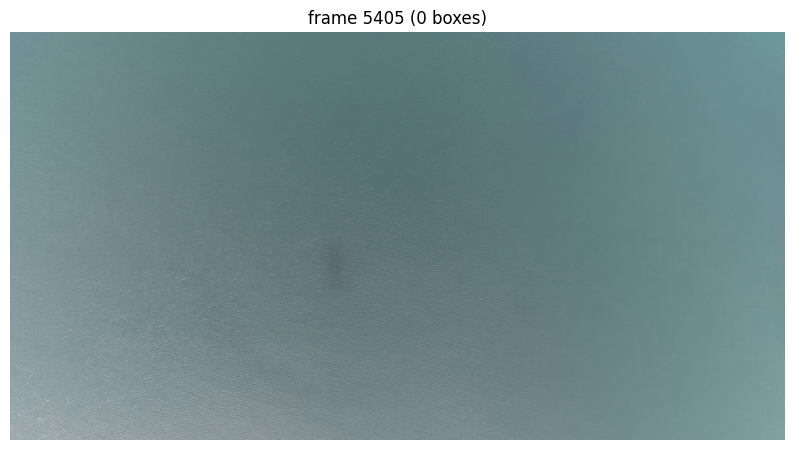

In [11]:
import json, re, collections
import matplotlib.pyplot as plt

# tools check (cv2 ships with Colab; install only if this fails)
try:
    import cv2
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "opencv-python-headless"])
    import cv2

DEST = "/content/drive/MyDrive/lifeguard_datasets/MOBDrone/annotations_5_custom_classes.json"
VIDEO = "/content/drive/MyDrive/lifeguard_datasets/MOBDrone/videos/DJI_0915_0007_40.mp4"
STEM = "DJI_0915_0007_40m"      # the annotation stem (note the trailing 'm')

d = json.load(open(DEST))
cat = {c["id"]: c["name"] for c in d["categories"]}
print("first annotation record (to confirm bbox format):", d["annotations"][0])

fn_to_id = {im["file_name"]: im["id"] for im in d["images"]}
anns = collections.defaultdict(list)
for a in d["annotations"]:
    anns[a["image_id"]].append((a["category_id"], a["bbox"]))

frame_boxes = {}
for im in d["images"]:
    if re.sub(r'_\d{6}\.PNG$', '', im["file_name"]) == STEM:
        idx = int(re.search(r'_(\d{6})\.PNG$', im["file_name"]).group(1))
        frame_boxes[idx] = anns.get(im["id"], [])

# pick first, last, 3 densest, 3 spread
densest = sorted(frame_boxes, key=lambda k: -len(frame_boxes[k]))[:3]
picks = sorted(set([0, max(frame_boxes)] + densest +
                   [len(frame_boxes)//4, len(frame_boxes)//2, 3*len(frame_boxes)//4]))
print("frames to check:", picks)

cap = cv2.VideoCapture(VIDEO)
for idx in picks:
    cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
    ret, frame = cap.read()
    if not ret:
        print(f"frame {idx}: FAILED to decode"); continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    fig, ax = plt.subplots(1, figsize=(10, 6)); ax.imshow(rgb)
    for cid, bbox in frame_boxes.get(idx, []):
        x, y, w, h = bbox            # COCO bbox = [x, y, width, height] (pixels)
        ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, edgecolor="red", lw=2))
        ax.text(x, max(0, y - 5), cat[cid], color="red", fontsize=9)
    ax.set_title(f"frame {idx} ({len(frame_boxes.get(idx, []))} boxes)"); ax.axis("off")
    plt.show()
cap.release()

In [ ]:

import os
from google.colab import drive

drive.mount("/content/drive")

RUN = "/content/drive/MyDrive/lifeguard_datasets/Z5cc_runs/z5cc_yolo11n_detect_v1"

print("Run folder exists:", os.path.isdir(RUN))

if os.path.isdir(RUN):
    for root, dirs, files in os.walk(RUN):
        for name in files:
            path = os.path.join(root, name)
            print(name, "|", os.path.getsize(path), "bytes")
else:
    print("Run folder not found at expected path.")
    print("\nSearching Z5cc_runs for matching files...")

    BASE = "/content/drive/MyDrive/lifeguard_datasets/Z5cc_runs"
    if os.path.isdir(BASE):
        for root, dirs, files in os.walk(BASE):
            for name in files:
                if name.endswith((".pt", ".csv")):
                    print(os.path.join(root, name))
    else:
        print("Z5cc_runs folder also not found.")
